In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/batter_seasons.parquet")
print(df.shape)

# Only keep players who faced enough balls for the stats to mean something
q = df[df["balls_faced"] >= 60].copy()
print("qualified player-seasons:", len(q))

print(q.sort_values("runs", ascending=False).head(10)[["player", "year", "runs", "strike_rate", "average"]])
print(q[(q["player"] == "V Kohli") & (q["year"] == 2016)])

(2959, 14)
qualified player-seasons: 1320
               player  year  runs  strike_rate    average
2775          V Kohli  2016   973   152.031250  81.083333
2641     Shubman Gill  2023   890   157.801418  59.333333
1004       JC Buttler  2022   863   149.050086  57.533333
595         DA Warner  2016   848   151.428571  60.571429
2807    V Suryavanshi  2026   776   237.308869  48.500000
401   B Sai Sudharsan  2025   759   156.172840  54.214286
2783          V Kohli  2024   741   154.697286  61.750000
1257    KS Williamson  2018   735   142.441860  52.500000
1484       MEK Hussey  2013   733   129.505300  56.384615
495          CH Gayle  2012   733   160.745614  61.083333
       player  year  matches  runs  balls_faced  fours  sixes  dots  \
2775  V Kohli  2016       16   973          640     83     38   169   

      dismissals  strike_rate    average  boundary_pct   dot_pct  \
2775          12    152.03125  81.083333      18.90625  26.40625   

      balls_per_dismissal  
2775        

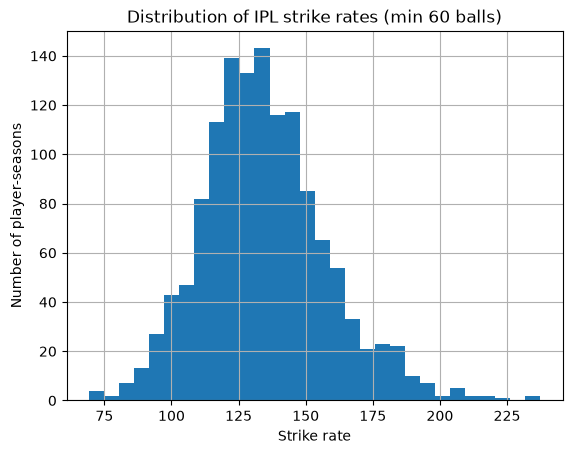

In [2]:
q["strike_rate"].hist(bins=30)
plt.xlabel("Strike rate")
plt.ylabel("Number of player-seasons")
plt.title("Distribution of IPL strike rates (min 60 balls)")
plt.show()

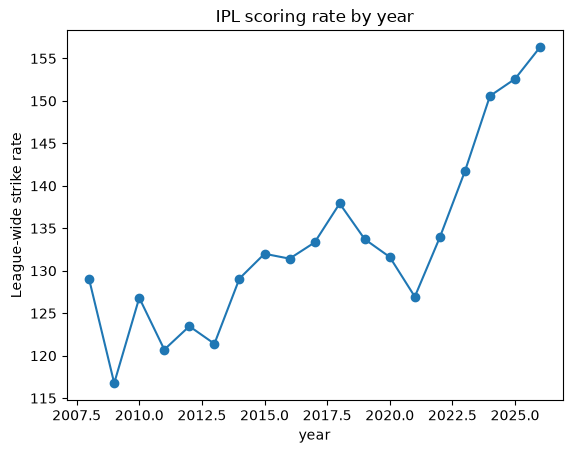

In [3]:
by_year = df.groupby("year").apply(lambda g: g["runs"].sum() / g["balls_faced"].sum() * 100)
by_year.plot(marker="o")
plt.ylabel("League-wide strike rate")
plt.title("IPL scoring rate by year")
plt.show()

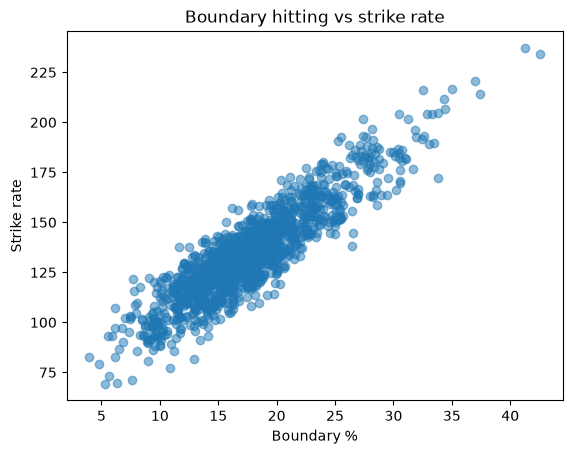

In [4]:
plt.scatter(q["boundary_pct"], q["strike_rate"], alpha=0.5)
plt.xlabel("Boundary %")
plt.ylabel("Strike rate")
plt.title("Boundary hitting vs strike rate")
plt.show()